In [1]:
import tensorflow as tf
import keras

print(tf.__version__)
print(keras.__version__)

2.21.0
3.15.1


In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

ROOT = Path.cwd()                 # Folder containing this notebook
DATA = ROOT / "data"
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)

print("Dataset found:", DATA.is_dir(), "| Folder:", DATA)

TensorFlow: 2.21.0
Dataset found: True | Folder: r:\potato_disease_cnn\data


In [3]:
classes = sorted(p.name for p in DATA.iterdir() if p.is_dir()) if  DATA.exists() else []

counts = {name: len( [ p for p in (DATA/name).iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]) for name in classes}
print("images per class :", counts)

#optional :
assert len (classes) == 3 and all(v >0 for v in counts.values()), "Dataset should have 3 classes with at least one image each"



images per class : {'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Potato___healthy': 152}


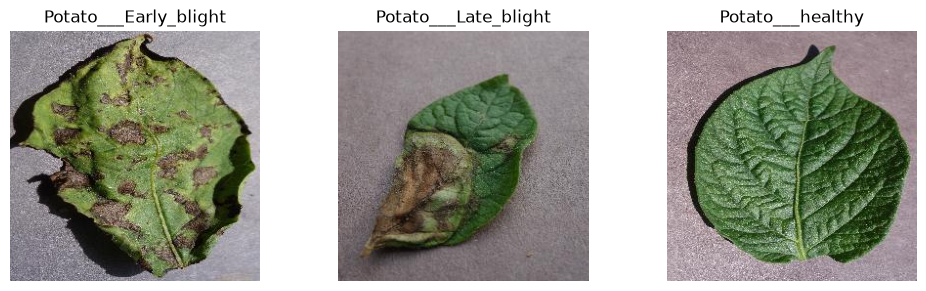

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for i, name in zip(axes, classes):
    folder = DATA/name
    file=next(p for p in folder.iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"])
    with Image.open(file) as img:
        img = img.convert("RGB")
        i.imshow(img)
        i.set_title(name)
        i.axis("off")   
plt.tight_layout()
plt.show()

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory( DATA, validation_split=0.2,subset="training",seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE,color_mode="rgb",label_mode="int")

val_ds = tf.keras.utils.image_dataset_from_directory( DATA, validation_split=0.2,subset="validation",seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE,color_mode="rgb",label_mode="int")


class_names = train_ds.class_names

images , labels = next(iter(train_ds))

print("class order ", class_names)
print("images in one batch ", images.shape )
print("labels in one batch ", labels[:32].numpy())

Found 2152 files belonging to 3 classes.
Using 1722 files for training.
Found 2152 files belonging to 3 classes.
Using 430 files for validation.
class order  ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
images in one batch  (32, 128, 128, 3)
labels in one batch  [0 1 2 1 0 0 0 0 1 1 1 1 0 0 1 1 1 1 2 2 1 1 1 0 1 0 0 1 1 0 0 1]


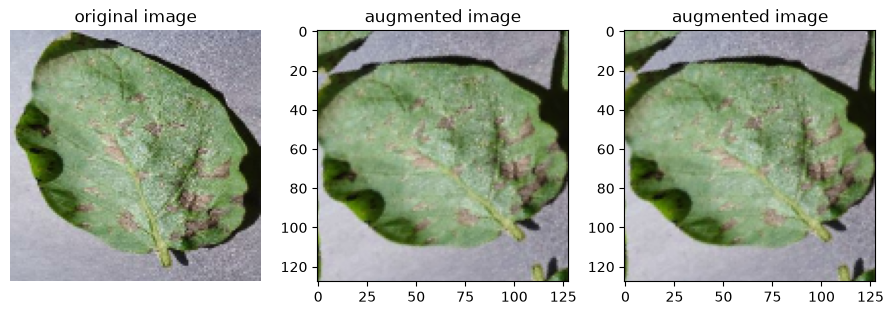

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [6]:
augmentation=tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
   
])

sample=images[0:1]
fig , axes = plt.subplots(1,3, figsize=(9,3))
axes[0].imshow(tf.cast(sample[0], tf.uint8 ))
axes[0].set_title("original image")

for i in (1,2):
    augmented=augmentation(sample,training=True)[0]
    axes[i].imshow(tf.cast(tf.clip_by_value(augmented, 0,255),tf.uint8))

    axes[i].set_title("augmented image") 

for i in axes:
    i.axis("off")
    plt.tight_layout()
    plt.show()

In [7]:
model=tf.keras.Sequential([
    tf.keras.Input(shape=(128,128,3)),
    tf.keras.layers.Rescaling(1.0/255),
    augmentation,

    #  feature extractor
    tf.keras.layers.Conv2D(16,3 , padding= "same", activation="relu"), 
    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Conv2D(32,3 ,padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),


    tf.keras.layers.Conv2D(64,3 ,padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # flatten
    tf.keras.layers.Flatten(),


    # classifier
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation="softmax")


])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,419 (4.09 MB)

 Trainable params: 1,072,419 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# model compile 
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# y vale part ko extract krege 
train_labels =np.concatenate([y.numpy() for _,y in train_ds])

# class count krege
class_counts = np.bincount(train_labels , minlength=len(class_names))
#class weights
class_weights={i: len(train_labels)/(len(class_names)*count) for i,count in enumerate(class_counts) }

# zip bind kr rha h names and count dono ko 
print("training class counts:", dict(zip(class_names,class_counts)))
print("class weights:", class_weights)

training class counts: {'Potato___Early_blight': np.int64(818), 'Potato___Late_blight': np.int64(792), 'Potato___healthy': np.int64(112)}
class weights: {0: np.float64(0.7017114914425427), 1: np.float64(0.7247474747474747), 2: np.float64(5.125)}


In [9]:
history=model.fit(train_ds,validation_data=val_ds, epochs=8, class_weight=class_weights)

Epoch 1/8


r:\potato_disease_cnn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


54/54 ━━━━━━━━━━━━━━━━━━━━ 19s 273ms/step - accuracy: 0.5952 - loss: 0.8481 - val_accuracy: 0.8116 - val_loss: 0.4168
Epoch 2/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - accuracy: 0.7880 - loss: 0.4465 - val_accuracy: 0.7860 - val_loss: 0.5518
Epoch 3/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 236ms/step - accuracy: 0.8566 - loss: 0.3459 - val_accuracy: 0.9000 - val_loss: 0.2765
Epoch 4/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 233ms/step - accuracy: 0.8931 - loss: 0.2526 - val_accuracy: 0.8349 - val_loss: 0.3743
Epoch 5/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 240ms/step - accuracy: 0.9204 - loss: 0.1788 - val_accuracy: 0.9186 - val_loss: 0.1932
Epoch 6/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 12s 227ms/step - accuracy: 0.9326 - loss: 0.1789 - val_accuracy: 0.8860 - val_loss: 0.4068
Epoch 7/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - accuracy: 0.9036 - loss: 0.2197 - val_accuracy: 0.9209 - val_loss: 0.2032
Epoch 8/8
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 234ms/step - accuracy: 0.9419 - loss: 0.1488 - val_accuracy: 0.9000 - val

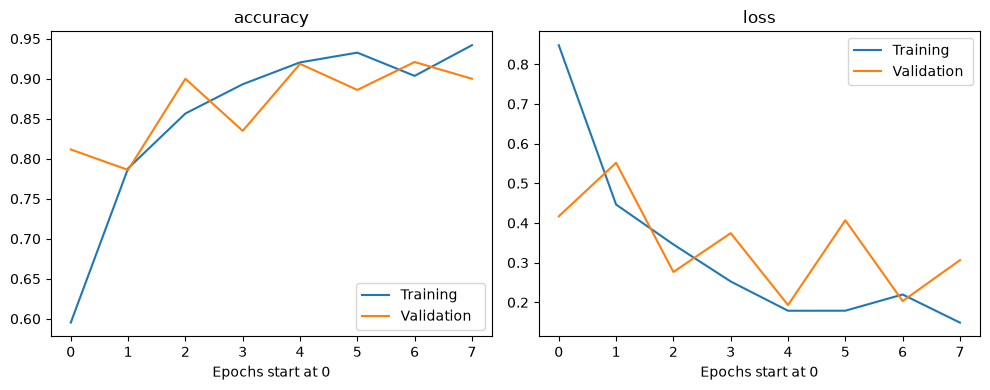

In [10]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training  ') 
plt.plot(history.history['val_accuracy'], label='Validation  ')
plt.title('accuracy')
plt.xlabel('Epochs start at 0')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training ')
plt.plot(history.history['val_loss'], label='Validation ')
plt.title('loss')
plt.xlabel('Epochs start at 0')
plt.legend()    


plt.tight_layout()
plt.show()

confusion matrix and classification report


validation accuracy:0.90 not test accuracy


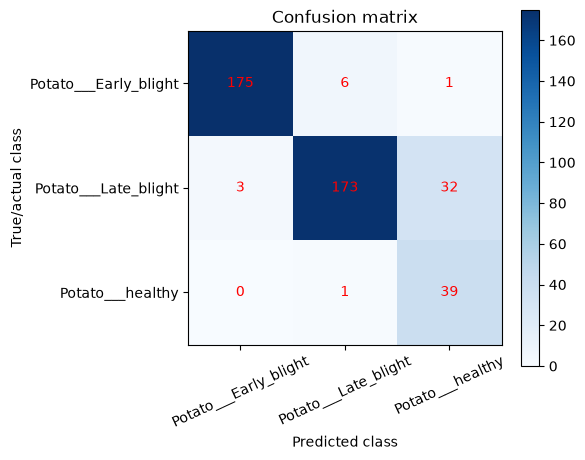

In [11]:
all_true,all_pred=[],[]
for batch_images,batch_labels in val_ds:
    scores=model.predict(batch_images,verbose=0)
    all_true.extend(batch_labels.numpy())
    all_pred.extend(np.argmax(scores,axis=1))

matrix=tf.math.confusion_matrix(all_true,all_pred,num_classes=len(class_names)).numpy()

accuracy=np.mean(np.array(all_true)==np.array(all_pred))
print(f"validation accuracy:{accuracy:.2f} not test accuracy")

plt.figure(figsize=(6,5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar()

plt.xticks(range(3),[s.replace("potato__","") for s in class_names],rotation=25)
plt.yticks(range(3),[s.replace("potato__","") for s in class_names]) 
plt.xlabel("Predicted class")
plt.ylabel("True/actual class")
plt.title("Confusion matrix")  


for i in range(3):
    for j in range(3):
        plt.text(j,i, matrix[i,j], ha="center", va="center", color="red")
plt.tight_layout()
plt.show()

In [12]:
model.save("potato_cnn_model.keras")
Path("classification_report.txt").write_text("\n".join(class_names),encoding="utf-8")
print("model saved to potato_cnn_model.keras and class names saved to classification_report.txt")

model saved to potato_cnn_model.keras and class names saved to classification_report.txt


model score 1.00
Potato___Early_blight : 1.00
Potato___Late_blight : 0.00
Potato___healthy : 0.00


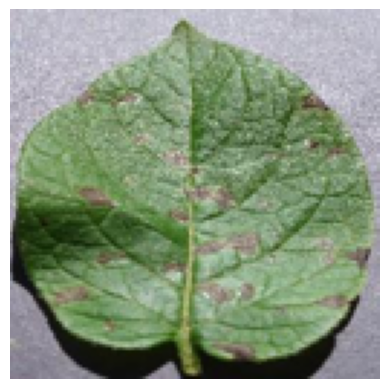

In [13]:
image_path = ROOT / "leaf.JPG"
if image_path.is_file():
    with Image.open(image_path) as file:
        image = file.convert("RGB").resize(IMG_SIZE)
    x=np.expand_dims(np.array(image,dtype=np.float32),axis=0)
    scores=model.predict(x,verbose=0)[0]
    best= int(np.argmax(scores))
    print("model score",f"{scores[best]:.2f}")
    for name, score in zip(class_names,scores):
        print(f"{name.replace('potato__','')} : {score:.2f}")
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print(" place an image named leaf.jpg beside this notebook and run cell again")